In [8]:
# INSTALL AND IMPORT LIBRARIES

!pip -q install -U xgboost

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

## LOAD DATASET

In [9]:
uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)
df.columns = df.columns.astype(str).str.strip()

# Remove automatically generated index columns.
df = df.loc[
    :,
    ~df.columns.str.match(r"^Unnamed:", case=False)
].copy()

print("Raw dataset shape:", df.shape)
print("Raw columns:", df.columns.tolist())

display(df.head())

Saving cert_preprocessed_ml_comparison.csv to cert_preprocessed_ml_comparison (5).csv
Raw dataset shape: (4615, 8)
Raw columns: ['file', 'id', 'timestamp', 'user', 'pc', 'activity', 'resource', 'case id;Cattivi']


,file,id,timestamp,user,pc,activity,resource,case id;Cattivi
0,logon,{U1Q4-I9PX02PE-8712XJDX},02/24/2011 19:49:41,WDD0366,PC-0155,Logon,WDD0366,17;1
1,device,{Q6W3-A2AY45RM-4749NTDA},02/24/2011 22:07:28,WDD0366,PC-0155,Connect,WDD0366,17;1
2,http,{S3I7-R3CN14RD-1922CYQD},02/24/2011 22:29:04,WDD0366,PC-0155,http://wikileaks.org/Julian_Assange/assange/Th...,WDD0366,17;1
3,device,{J3N5-J1IG44ZN-4509ZXOG},02/24/2011 22:31:31,WDD0366,PC-0155,Disconnect,WDD0366,17;1
4,logon,{V5E4-F1JY53FG-8030MANZ},02/24/2011 23:11:08,WDD0366,PC-0155,Logoff,WDD0366,17;1


## RECONSTRUCT THE TWO DIFFERENT ROW LAYOUTS

In [10]:
combined_column = "case id;Cattivi"

if combined_column not in df.columns:
    raise ValueError(
        f"Expected combined column '{combined_column}' not found. "
        f"Actual columns: {df.columns.tolist()}"
    )

required_columns = [
    "file", "id", "timestamp", "user", "pc",
    "activity", "resource", combined_column
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from input: {missing_columns}"
    )

# Layout B is identified by a missing combined case/label field.
shifted_rows = df[combined_column].isna()

print("\nRows in original layout:", (~shifted_rows).sum())
print("Rows in shifted layout:", shifted_rows.sum())


Rows in original layout: 1274
Rows in shifted layout: 3341


In [11]:
# Preserve original values before modifying the rows.
old_file = df["file"].copy()
old_id = df["id"].copy()
old_timestamp = df["timestamp"].copy()
old_user = df["user"].copy()
old_pc = df["pc"].copy()
old_activity = df["activity"].copy()
old_combined = df[combined_column].copy()

# Reconstruct Layout B into the common column structure.
df.loc[shifted_rows, "file"] = pd.NA
df.loc[shifted_rows, "id"] = old_file[shifted_rows]
df.loc[shifted_rows, "timestamp"] = old_id[shifted_rows]
df.loc[shifted_rows, "user"] = old_pc[shifted_rows]
df.loc[shifted_rows, "pc"] = old_timestamp[shifted_rows]
df.loc[shifted_rows, "activity"] = old_user[shifted_rows]
df.loc[shifted_rows, "resource"] = pd.NA

# Extract case ID and label from the appropriate original field.
case_label = old_combined.copy()
case_label.loc[shifted_rows] = old_activity.loc[shifted_rows]

parts = case_label.astype("string").str.extract(
    r"^\s*(\d+)\s*;\s*([01])\s*$"
)

df["case_id"] = pd.to_numeric(parts[0], errors="coerce")
df["Cattivi"] = pd.to_numeric(parts[1], errors="coerce")

# Verify all rows have a recoverable case ID and binary label.
if df["Cattivi"].isna().any():
    display(
        df.loc[
            df["Cattivi"].isna(),
            ["id", "timestamp", "activity", combined_column]
        ].head(10)
    )
    raise ValueError(
        "Some rows have no recoverable binary label. "
        "Inspect the displayed rows and source CSV."
    )

if df["case_id"].isna().any():
    display(
        df.loc[
            df["case_id"].isna(),
            ["id", "timestamp", "activity"]
        ].head(10)
    )
    raise ValueError(
        "Some rows have no recoverable case ID. "
        "Inspect the original CSV structure."
    )

df["Cattivi"] = df["Cattivi"].astype(int)
df["case_id"] = df["case_id"].astype(int)

# Remove the original combined field.
df.drop(columns=[combined_column], inplace=True)

print("\nReconstructed dataset shape:", df.shape)
print("\nTarget counts:")
print(df["Cattivi"].value_counts().sort_index())

print("\nTarget proportions:")
print(df["Cattivi"].value_counts(normalize=True).sort_index().round(3))

if set(df["Cattivi"].unique()) != {0, 1}:
    raise ValueError("Expected both target classes: 0 and 1.")

print("\nSample reconstructed rows:")
display(df.head())

print("\nSample rows from the reconstructed block:")
display(df.iloc[1274:1280])


Reconstructed dataset shape: (4615, 9)

Target counts:
Cattivi
0    3341
1    1274
Name: count, dtype: int64

Target proportions:
Cattivi
0    0.724
1    0.276
Name: proportion, dtype: float64

Sample reconstructed rows:


,file,id,timestamp,user,pc,activity,resource,case_id,Cattivi
0,logon,{U1Q4-I9PX02PE-8712XJDX},02/24/2011 19:49:41,WDD0366,PC-0155,Logon,WDD0366,17,1
1,device,{Q6W3-A2AY45RM-4749NTDA},02/24/2011 22:07:28,WDD0366,PC-0155,Connect,WDD0366,17,1
2,http,{S3I7-R3CN14RD-1922CYQD},02/24/2011 22:29:04,WDD0366,PC-0155,http://wikileaks.org/Julian_Assange/assange/Th...,WDD0366,17,1
3,device,{J3N5-J1IG44ZN-4509ZXOG},02/24/2011 22:31:31,WDD0366,PC-0155,Disconnect,WDD0366,17,1
4,logon,{V5E4-F1JY53FG-8030MANZ},02/24/2011 23:11:08,WDD0366,PC-0155,Logoff,WDD0366,17,1



Sample rows from the reconstructed block:


,file,id,timestamp,user,pc,activity,resource,case_id,Cattivi
1274,<NA>,{Z0P3-J7FZ22QC-5002NTTT},2010-02-23 15:43:45,SBN0971,PC-0151,consult http,<NA>,17,0
1275,<NA>,{F9Z6-O4WQ98FV-8997DBMR},2011-01-07 08:23:48,WDD0366,PC-0155,consult http,<NA>,17,0
1276,<NA>,{M0O5-I8DI39BC-8847GLCK},2010-10-20 13:29:16,WDD0366,PC-0155,consult http,<NA>,17,0
1277,<NA>,{O1W2-L7LV03SC-2656WPQI},2010-06-21 11:29:32,WDD0366,PC-0155,consult http,<NA>,17,0
1278,<NA>,{M3C1-S4MQ48SI-3575ZWQI},2010-11-16 08:18:16,WDD0366,PC-0155,consult http,<NA>,17,0
1279,<NA>,{I0M2-U3OS63IA-3635YJQB},2010-05-10 09:00:44,WDD0366,PC-0155,consult http,<NA>,17,0


## DATA QUALITY CHECKS AND EXPLORATORY DATA ANALYSIS

In [12]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4615 entries, 0 to 4614
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file       1274 non-null   object
 1   id         4615 non-null   object
 2   timestamp  4615 non-null   object
 3   user       4615 non-null   object
 4   pc         4615 non-null   object
 5   activity   4615 non-null   object
 6   resource   1274 non-null   object
 7   case_id    4615 non-null   int64 
 8   Cattivi    4615 non-null   int64 
dtypes: int64(2), object(7)
memory usage: 324.6+ KB


In [13]:
print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing Values"))


Missing values by column:


,Missing Values
file,3341
id,0
timestamp,0
user,0
pc,0
activity,0
resource,3341
case_id,0
Cattivi,0


In [14]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


# Target variable distribution

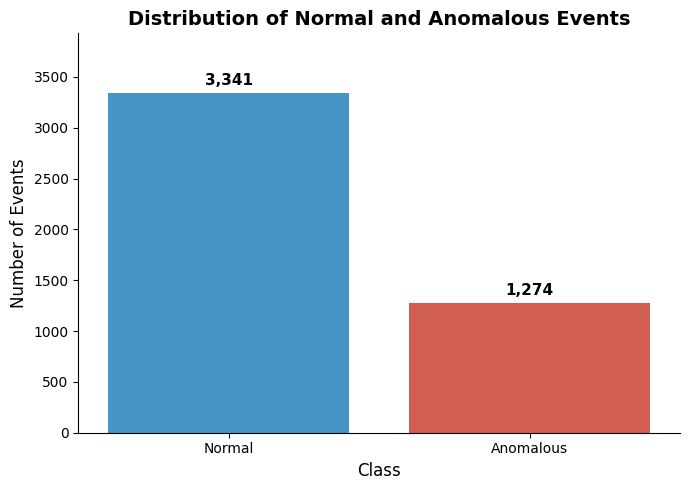

In [34]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Cattivi",
    hue="Cattivi",
    palette={0: "#3498DB", 1: "#E74C3C"},
    legend=False
)

plt.title("Distribution of Normal and Anomalous Events", fontsize=14, weight="bold")
plt.xlabel("Class", fontsize=12)
plt.ylabel("Number of Events", fontsize=12)
plt.xticks([0, 1], ["Normal", "Anomalous"])

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.ylim(0, ax.get_ylim()[1] * 1.12)
sns.despine()
plt.tight_layout()
plt.show()

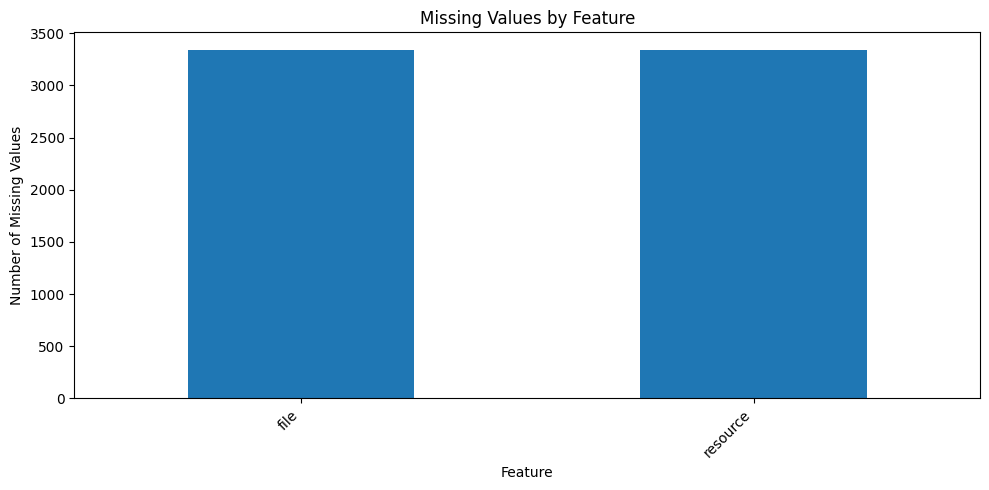

In [16]:
# Missing-value visualisation.
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(10, 5))
    missing.plot(kind="bar")

    plt.title("Missing Values by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

In [17]:
# Inspect label distribution by case ID.
case_summary = (
    df.groupby("case_id")["Cattivi"]
      .agg(["count", "nunique", "first"])
      .rename(columns={
          "count": "Number of records",
          "nunique": "Number of distinct labels",
          "first": "First label"
      })
)

print("\nNumber of distinct case IDs:", df["case_id"].nunique())
print("\nCase IDs with more than one target label:")
display(case_summary[case_summary["Number of distinct labels"] > 1].head(20))


Number of distinct case IDs: 21

Case IDs with more than one target label:


,Number of records,Number of distinct labels,First label
case_id,,,
11,181,2,1
17,185,2,1
93,191,2,1
164,186,2,1
182,181,2,1
201,394,2,1
233,186,2,1
253,191,2,1
257,185,2,1


## FEATURE ENGINEERING

In [18]:
# Parse the normalized timestamp column.
df["parsed_timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
    format="mixed"
)

invalid_timestamp_count = df["parsed_timestamp"].isna().sum()
print("\nTimestamps that could not be parsed:", invalid_timestamp_count)

df["event_hour"] = df["parsed_timestamp"].dt.hour
df["event_day"] = df["parsed_timestamp"].dt.day
df["event_month"] = df["parsed_timestamp"].dt.month
df["event_weekday"] = df["parsed_timestamp"].dt.dayofweek

df["is_weekend"] = np.where(
    df["parsed_timestamp"].notna(),
    (df["parsed_timestamp"].dt.dayofweek >= 5).astype(float),
    np.nan
)

df["is_outside_working_hours"] = np.where(
    df["parsed_timestamp"].notna(),
    (
        (df["parsed_timestamp"].dt.hour < 8) |
        (df["parsed_timestamp"].dt.hour >= 18)
    ).astype(float),
    np.nan
)

# Drop raw timestamp after extracting temporal features.
df.drop(
    columns=["timestamp", "parsed_timestamp"],
    inplace=True
)


Timestamps that could not be parsed: 0


## SELECT MODEL FEATURES AND TARGET

In [19]:
TARGET_COLUMN = "Cattivi"

# Exclude IDs and direct identifiers.
excluded_columns = [
    "id",
    "case_id",
    "user",
    "pc",
    "resource",
    "file"
]

drop_columns = [
    col for col in excluded_columns
    if col in df.columns
]

X = df.drop(
    columns=[TARGET_COLUMN] + drop_columns,
    errors="ignore"
).copy()

y = df[TARGET_COLUMN].copy()

# Remove features that are all missing or constant.
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_columns:
    X.drop(columns=constant_columns, inplace=True)
    print("\nRemoved constant/all-missing features:", constant_columns)

print("\nExcluded columns:", drop_columns)
print("\nSelected model features:", X.columns.tolist())
print("Feature matrix shape:", X.shape)

if X.shape[1] == 0:
    raise ValueError("No usable features remain after feature selection.")

# Inspect activity/label association for possible label leakage.
if "activity" in df.columns:
    print("\nActivity counts by target:")
    display(pd.crosstab(df["activity"], y, margins=True))

    print("\nActivity proportions within each target class:")
    display(
        pd.crosstab(
            df["activity"],
            y,
            normalize="columns"
        ).round(3)
    )


Excluded columns: ['id', 'case_id', 'user', 'pc', 'resource', 'file']

Selected model features: ['activity', 'event_hour', 'event_day', 'event_month', 'event_weekday', 'is_weekend', 'is_outside_working_hours']
Feature matrix shape: (4615, 7)

Activity counts by target:


Cattivi,0,1,All
activity,,,
Connect,81,224,305
Disconnect,81,224,305
Logoff,85,32,117
Logon,112,32,144
consult file,93,0,93
consult http,2607,670,3277
http://wikileaks.org/Julian_Assange/assange/The_Real_Story_About_DTAA/Gur_Erny_Fgbel_Nobhg_QGNN1528513805.php,0,32,32
send email,282,60,342
All,3341,1274,4615



Activity proportions within each target class:


Cattivi,0,1
activity,,
Connect,0.024,0.176
Disconnect,0.024,0.176
Logoff,0.025,0.025
Logon,0.034,0.025
consult file,0.028,0.000
consult http,0.780,0.526
http://wikileaks.org/Julian_Assange/assange/The_Real_Story_About_DTAA/Gur_Erny_Fgbel_Nobhg_QGNN1528513805.php,0.000,0.025
send email,0.084,0.047


## CASE-GROUPED TRAIN/TEST SPLIT

In [35]:
groups = df["case_id"].copy()

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_splits = list(outer_cv.split(X, y, groups=groups))

valid_outer_splits = []

for train_idx, test_idx in outer_splits:
    train_classes = set(y.iloc[train_idx].unique())
    test_classes = set(y.iloc[test_idx].unique())

    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])

    no_group_overlap = train_groups.isdisjoint(test_groups)

    if (
        train_classes == {0, 1}
        and test_classes == {0, 1}
        and no_group_overlap
    ):
        valid_outer_splits.append((train_idx, test_idx))

if not valid_outer_splits:
    raise ValueError(
        "Could not create a valid grouped train/test split with both "
        "classes in each partition. Check the number of case IDs and "
        "their label distribution. Do not replace this with a random "
        "row split without explaining the limitation."
    )

train_idx, test_idx = valid_outer_splits[0]

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("\nGrouped training set shape:", X_train.shape)
print("Grouped testing set shape:", X_test.shape)

print("\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\nTesting class counts:")
print(y_test.value_counts().sort_index())

print("\nTraining case groups:", groups_train.nunique())
print("Testing case groups:", groups_test.nunique())
print("Overlapping case IDs:", len(set(groups_train) & set(groups_test)))

if not set(y_train.unique()) == {0, 1}:
    raise ValueError("Training partition does not contain both classes.")

if not set(y_test.unique()) == {0, 1}:
    raise ValueError("Testing partition does not contain both classes.")


Grouped training set shape: (3457, 7)
Grouped testing set shape: (1158, 7)

Training class counts:
Cattivi
0    2637
1     820
Name: count, dtype: int64

Testing class counts:
Cattivi
0    704
1    454
Name: count, dtype: int64

Training case groups: 17
Testing case groups: 4
Overlapping case IDs: 0


## PREPROCESSING PIPELINE

In [21]:
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    )
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)



Numeric features: ['event_hour', 'event_day', 'event_month', 'event_weekday', 'is_weekend', 'is_outside_working_hours']
Categorical features: ['activity']


## DEFINE CLASSIFICATION MODELS

In [22]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

## GROUPED FIVE-FOLD CROSS-VALIDATION

In [23]:
inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=43
)

inner_splits_all = list(
    inner_cv.split(X_train, y_train, groups=groups_train)
)

cv_splits = []

for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(
    inner_splits_all,
    start=1
):
    fold_train_classes = set(y_train.iloc[fold_train_idx].unique())
    fold_valid_classes = set(y_train.iloc[fold_valid_idx].unique())

    fold_train_groups = set(groups_train.iloc[fold_train_idx])
    fold_valid_groups = set(groups_train.iloc[fold_valid_idx])

    no_group_overlap = fold_train_groups.isdisjoint(fold_valid_groups)

    if (
        fold_train_classes == {0, 1}
        and fold_valid_classes == {0, 1}
        and no_group_overlap
    ):
        cv_splits.append((fold_train_idx, fold_valid_idx))
    else:
        print(
            f"Skipping fold {fold_number}: "
            f"train classes={fold_train_classes}, "
            f"validation classes={fold_valid_classes}, "
            f"group overlap={not no_group_overlap}"
        )

if len(cv_splits) < 2:
    raise ValueError(
        "Not enough valid grouped CV folds. There may be too few case "
        "groups or too few groups containing each class. Inspect the "
        "case summary and dataset structure before modeling."
    )

print(f"\nUsing {len(cv_splits)} valid grouped CV folds.")

cv_results = {}
cv_pipelines = {}

for model_name, classifier in models.items():
    print(f"\nCross-validating {model_name}...")

    fold_scores = []

    for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(
        cv_splits,
        start=1
    ):
        X_fold_train = X_train.iloc[fold_train_idx]
        y_fold_train = y_train.iloc[fold_train_idx]

        X_fold_valid = X_train.iloc[fold_valid_idx]
        y_fold_valid = y_train.iloc[fold_valid_idx]

        pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ])

        pipeline.fit(X_fold_train, y_fold_train)

        fold_probabilities = pipeline.predict_proba(X_fold_valid)[:, 1]

        fold_pr_auc = average_precision_score(
            y_fold_valid,
            fold_probabilities
        )

        fold_scores.append(fold_pr_auc)
        print(f"Fold {fold_number} PR-AUC: {fold_pr_auc:.4f}")

    cv_results[model_name] = {
        "Mean CV PR-AUC": np.mean(fold_scores),
        "Standard Deviation": np.std(fold_scores),
        "Fold Scores": fold_scores
    }

    print("Fold PR-AUC:", np.round(fold_scores, 4))
    print("Mean PR-AUC:", round(np.mean(fold_scores), 4))
    print("Standard deviation:", round(np.std(fold_scores), 4))

cv_df = pd.DataFrame({
    model_name: {
        "Mean CV PR-AUC": details["Mean CV PR-AUC"],
        "Standard Deviation": details["Standard Deviation"]
    }
    for model_name, details in cv_results.items()
}).T

print("\nGrouped cross-validation comparison:")
display(cv_df.round(4))

best_model_name = cv_df["Mean CV PR-AUC"].idxmax()
print("\nSelected model by mean grouped CV PR-AUC:", best_model_name)


Using 4 valid grouped CV folds.

Cross-validating Random Forest...
Fold 1 PR-AUC: 0.7003
Fold 2 PR-AUC: 0.3466
Fold 3 PR-AUC: 0.4577
Fold 4 PR-AUC: 0.4507
Fold PR-AUC: [0.7003 0.3466 0.4577 0.4507]
Mean PR-AUC: 0.4888
Standard deviation: 0.1298

Cross-validating XGBoost...
Fold 1 PR-AUC: 0.7441
Fold 2 PR-AUC: 0.4400
Fold 3 PR-AUC: 0.6568
Fold 4 PR-AUC: 0.4335
Fold PR-AUC: [0.7441 0.44   0.6568 0.4335]
Mean PR-AUC: 0.5686
Standard deviation: 0.1354

Grouped cross-validation comparison:


,Mean CV PR-AUC,Standard Deviation
Random Forest,0.4888,0.1298
XGBoost,0.5686,0.1354



Selected model by mean grouped CV PR-AUC: XGBoost


## TRAIN BOTH MODELS AND EVALUATE ON HELD-OUT TEST SET

In [24]:
trained_models = {}
results = []
predictions = {}
probabilities = {}

for model_name, classifier in models.items():
    print(f"\nTraining final {model_name} model...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

    print(f"\n{model_name} classification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Normal", "Anomalous"],
            zero_division=0
        )
    )

results_df = pd.DataFrame(results).set_index("Model")

print("\nHeld-out test-set model comparison:")
display(results_df.round(4))

best_model = trained_models[best_model_name]

print("\nSelected model:", best_model_name)
print(
    "Mean grouped CV PR-AUC:",
    round(cv_df.loc[best_model_name, "Mean CV PR-AUC"], 4)
)
print(
    "Held-out test PR-AUC:",
    round(results_df.loc[best_model_name, "PR-AUC"], 4)
)


Training final Random Forest model...

Random Forest classification report:
              precision    recall  f1-score   support

      Normal       0.61      0.92      0.73       704
   Anomalous       0.40      0.08      0.14       454

    accuracy                           0.59      1158
   macro avg       0.50      0.50      0.44      1158
weighted avg       0.53      0.59      0.50      1158


Training final XGBoost model...

XGBoost classification report:
              precision    recall  f1-score   support

      Normal       0.60      0.94      0.73       704
   Anomalous       0.33      0.05      0.08       454

    accuracy                           0.59      1158
   macro avg       0.47      0.49      0.41      1158
weighted avg       0.50      0.59      0.48      1158


Held-out test-set model comparison:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.5915,0.4000,0.0837,0.1384,0.5782,0.4483
XGBoost,0.5889,0.3333,0.0485,0.0846,0.4851,0.3829



Selected model: XGBoost
Mean grouped CV PR-AUC: 0.5686
Held-out test PR-AUC: 0.3829


## MODEL PERFORMANCE

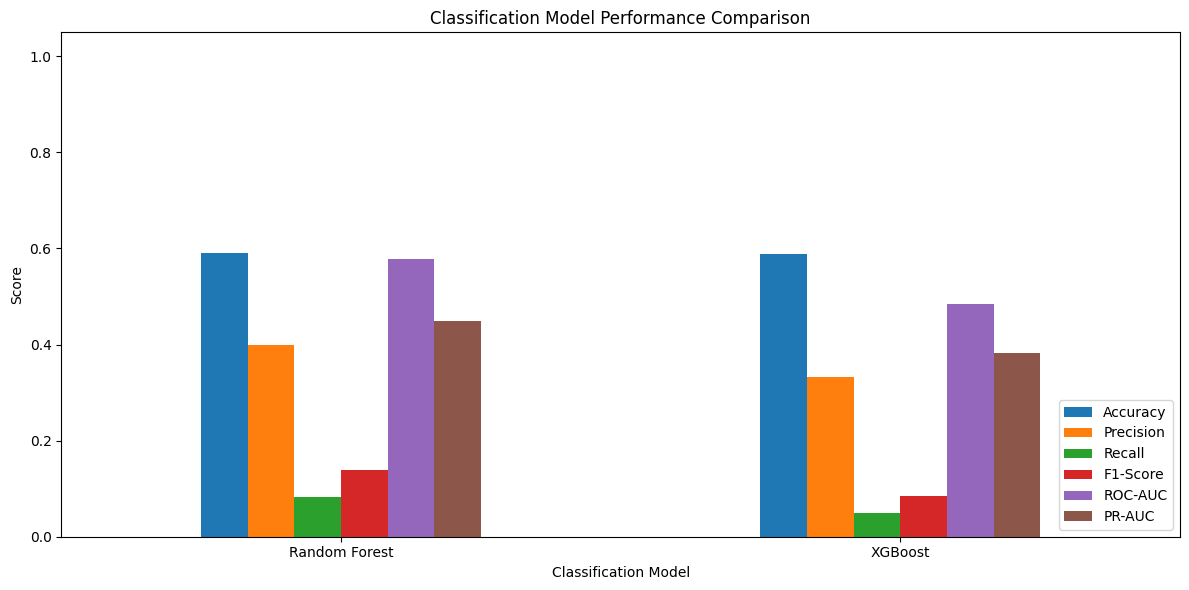

In [26]:
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

results_df[metric_columns].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


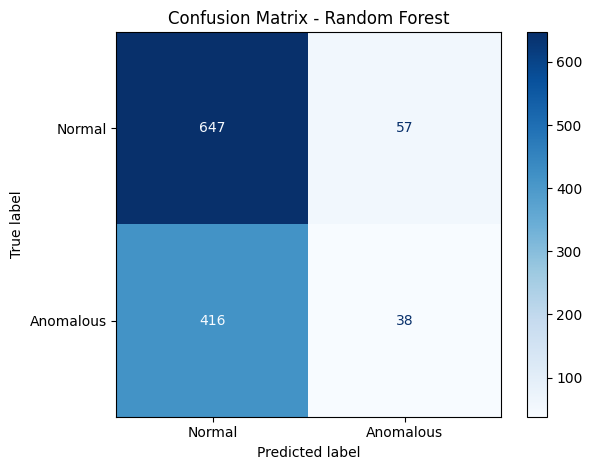

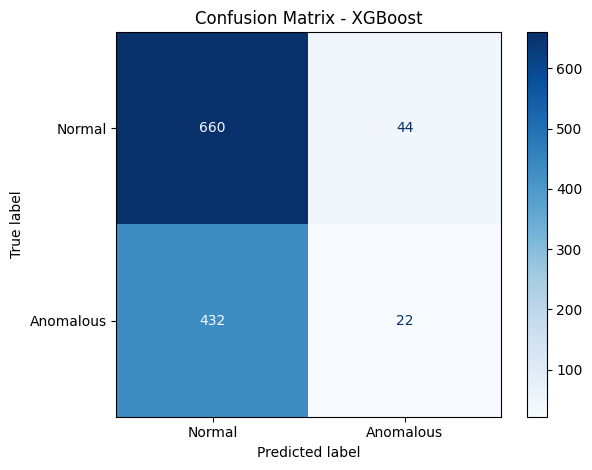

In [27]:
# Confusion matrices.
for model_name in models:
    cm = confusion_matrix(
        y_test,
        predictions[model_name],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Anomalous"]
    )

    disp.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

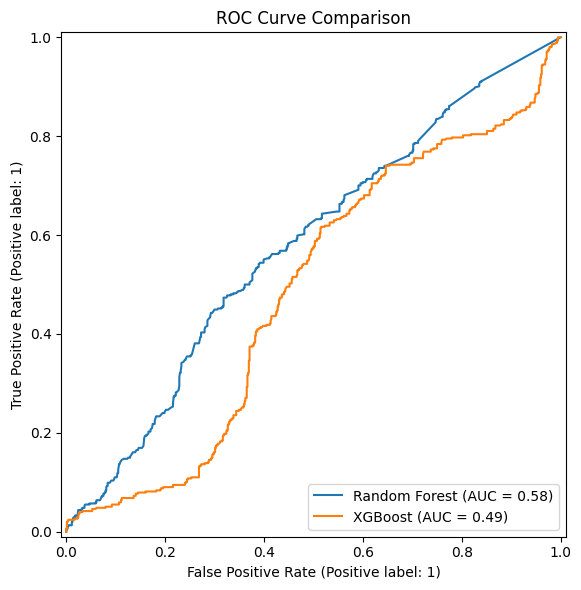

In [28]:
# ROC curves.
fig, ax = plt.subplots(figsize=(8, 6))

for model_name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[model_name],
        name=model_name,
        ax=ax
    )

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

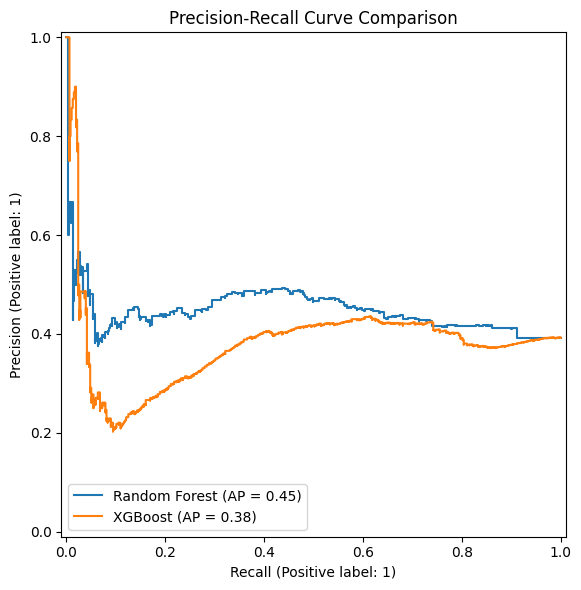

In [29]:
# Precision-recall curves.
fig, ax = plt.subplots(figsize=(8, 6))

for model_name in models:
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities[model_name],
        name=model_name,
        ax=ax
    )

plt.title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()


## FEATURE IMPORTANCE OF SELECTED MODEL


Top 15 features of selected model:


,Feature,Importance
6,categorical__activity_Connect,0.1559
7,categorical__activity_Disconnect,0.1428
10,categorical__activity_consult file,0.1247
13,categorical__activity_send email,0.1132
5,numeric__is_outside_working_hours,0.0666
8,categorical__activity_Logoff,0.0638
11,categorical__activity_consult http,0.0618
2,numeric__event_month,0.0580
9,categorical__activity_Logon,0.0528
12,categorical__activity_http://wikileaks.org/Jul...,0.0521


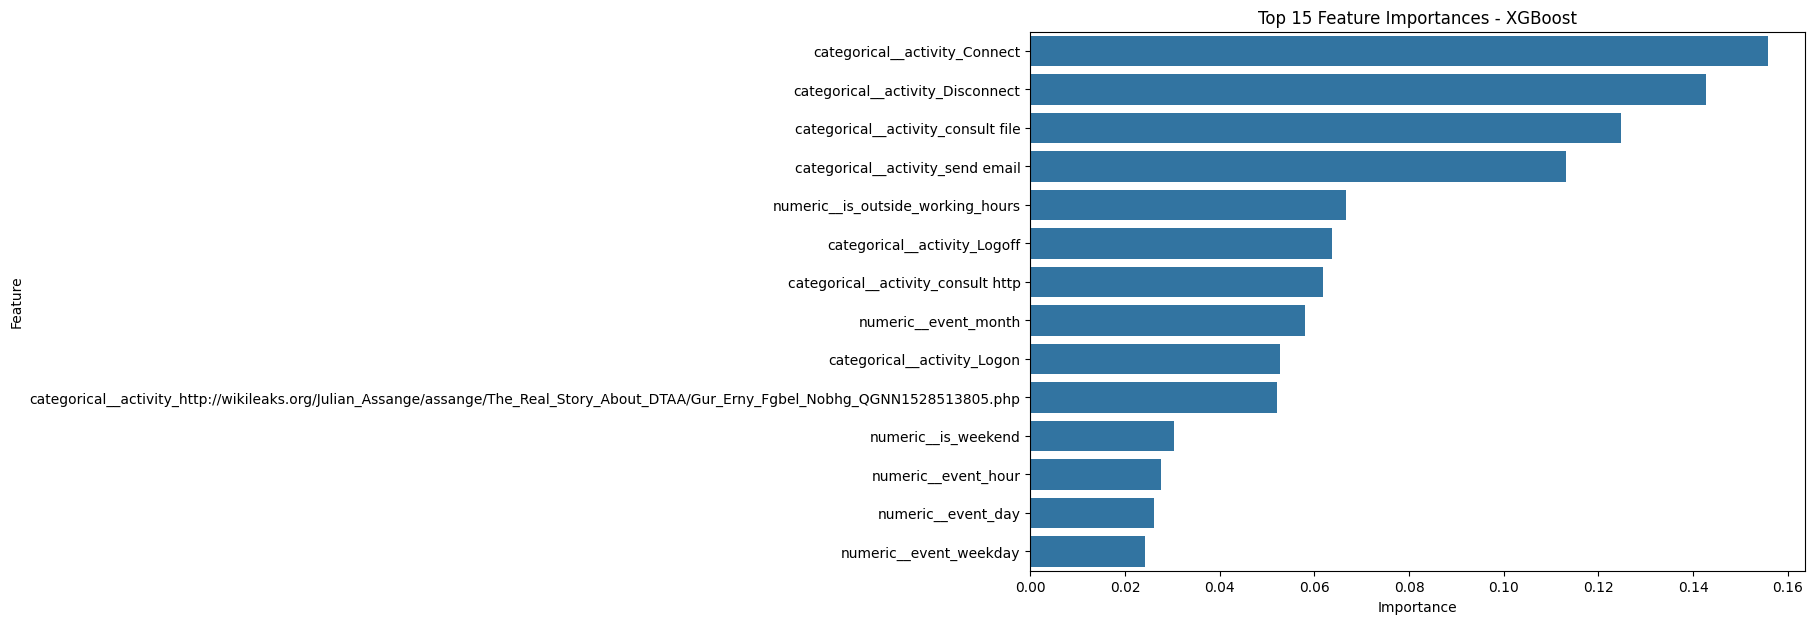

In [30]:
best_classifier = best_model.named_steps["classifier"]
best_preprocessor = best_model.named_steps["preprocessor"]

importance_df = None

if hasattr(best_classifier, "feature_importances_"):
    feature_names = best_preprocessor.get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": best_classifier.feature_importances_
    }).sort_values(
        by="Importance",
        ascending=False
    )

    print("\nTop 15 features of selected model:")
    display(importance_df.head(15).round(4))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title(f"Top 15 Feature Importances - {best_model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

## SAVE MODEL AND RESULTS FOR WEB APPLICATION

In [31]:
# Save the fitted pipeline, including preprocessing.
joblib.dump(
    best_model,
    "best_security_event_classifier.pkl"
)

results_df.to_csv("model_comparison_results.csv")
cv_df.to_csv("cross_validation_results.csv")

if importance_df is not None:
    importance_df.to_csv(
        "best_model_feature_importance.csv",
        index=False
    )

# Save the exact input columns expected by the fitted pipeline.
joblib.dump(
    X.columns.tolist(),
    "security_model_features.pkl"
)

model_metadata = {
    "selected_model": best_model_name,
    "target_column": TARGET_COLUMN,
    "normal_label": 0,
    "anomalous_label": 1,
    "input_features": X.columns.tolist(),
    "validation_method": "StratifiedGroupKFold grouped by case_id",
    "test_split_method": "First valid fold from StratifiedGroupKFold",
    "excluded_columns": drop_columns,
    "note": (
        "The reconstructed file column was excluded because it was "
        "not consistently available across the two original row layouts."
    )
}

joblib.dump(
    model_metadata,
    "security_model_metadata.pkl"
)

print("\nExport completed:")
print("- best_security_event_classifier.pkl")
print("- security_model_features.pkl")
print("- security_model_metadata.pkl")
print("- model_comparison_results.csv")
print("- cross_validation_results.csv")

if importance_df is not None:
    print("- best_model_feature_importance.csv")


# DOWNLOAD MODEL AND EVALUATION FILES

files.download("best_security_event_classifier.pkl")
files.download("security_model_features.pkl")
files.download("security_model_metadata.pkl")
files.download("model_comparison_results.csv")
files.download("cross_validation_results.csv")

if importance_df is not None:
    files.download("best_model_feature_importance.csv")


Export completed:
- best_security_event_classifier.pkl
- security_model_features.pkl
- security_model_metadata.pkl
- model_comparison_results.csv
- cross_validation_results.csv
- best_model_feature_importance.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>